<a href="https://colab.research.google.com/github/Jeetansh-Ruhela/Unlox-Program-Projects/blob/main/Minor_Project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic Survival Prediction using Random Forest
**Dataset:** [Kaggle — Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic)
**Task:** Binary classification — predict `Survived` (0 = No, 1 = Yes)
**Model:** Random Forest Classifier (with hyperparameter tuning + cross-validation)

In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [35]:
df = pd.read_csv("/content/train.csv")
print("Shape:", df.shape)

Shape: (891, 12)


In [36]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [37]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [39]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [40]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [41]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [42]:
print(df["Survived"].value_counts())
print("Positive rate: {:.2%}".format(df["Survived"].mean()))

Survived
0    549
1    342
Name: count, dtype: int64
Positive rate: 38.38%


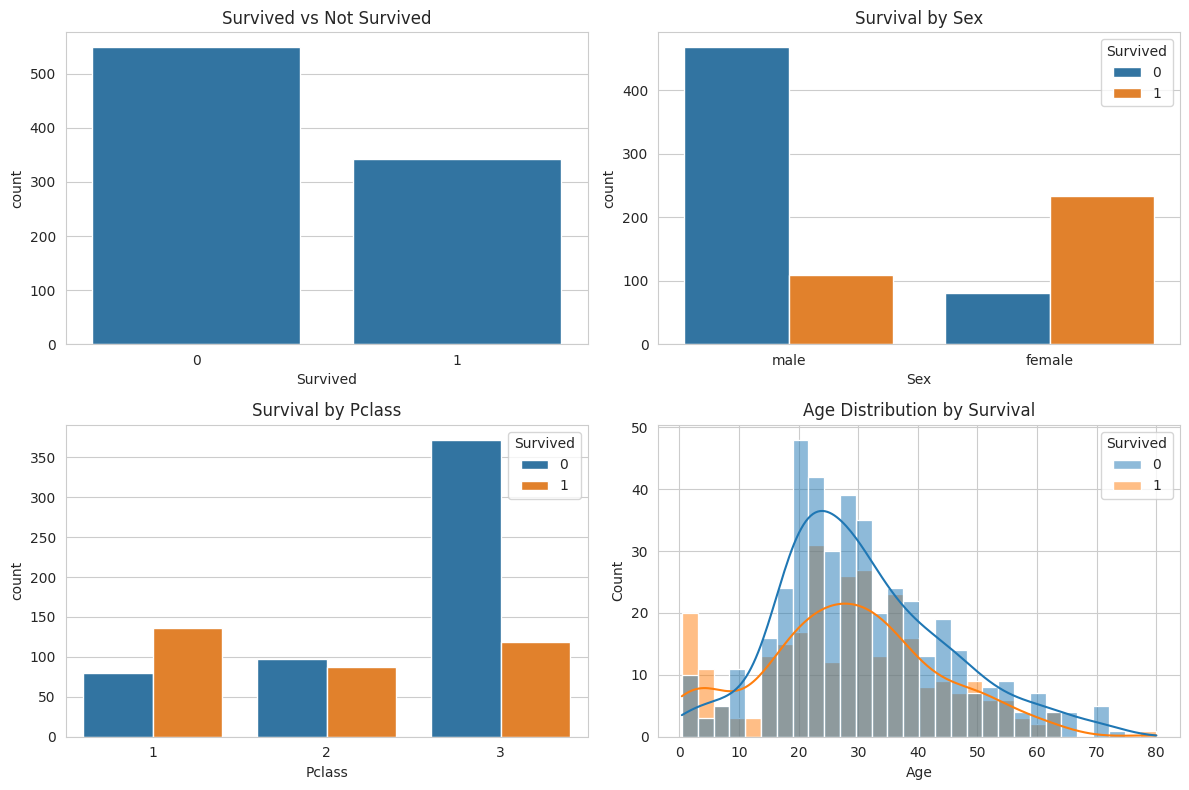

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=df, x="Survived", ax=axes[0, 0])
axes[0, 0].set_title("Survived vs Not Survived")

sns.countplot(data=df, x="Sex", hue="Survived", ax=axes[0, 1])
axes[0, 1].set_title("Survival by Sex")

sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[1, 0])
axes[1, 0].set_title("Survival by Pclass")

sns.histplot(data=df, x="Age", hue="Survived", kde=True, bins=30, ax=axes[1, 1])
axes[1, 1].set_title("Age Distribution by Survival")

plt.tight_layout()
plt.show()

In [44]:
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(
    lambda s: s.fillna(s.median())
)
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["HasCabin"] = df["Cabin"].notnull().astype(int)
df.drop(columns=["Cabin"], inplace=True)

print("Duplicates before:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicates after :", df.duplicated().sum())
print("Remaining missing values:", int(df.isnull().sum().sum()))

Duplicates before: 0
Duplicates after : 0
Remaining missing values: 0


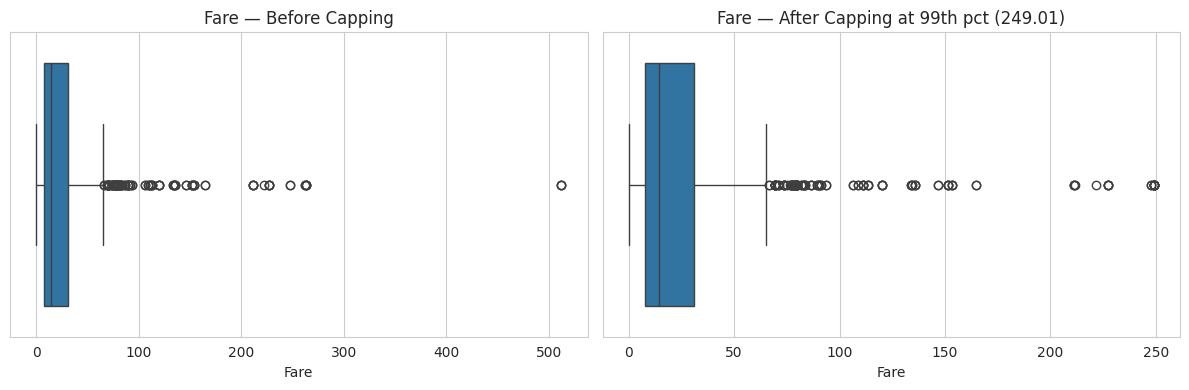

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Fare", ax=axes[0])
axes[0].set_title("Fare — Before Capping")

fare_cap = df["Fare"].quantile(0.99)
df["Fare"] = np.where(df["Fare"] > fare_cap, fare_cap, df["Fare"])

sns.boxplot(data=df, x="Fare", ax=axes[1])
axes[1].set_title(f"Fare — After Capping at 99th pct ({fare_cap:.2f})")

plt.tight_layout()
plt.show()

In [46]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]*)\.")

rare_titles = ["Dr", "Rev", "Col", "Major", "Capt", "Countess", "Don",
               "Jonkheer", "Lady", "Sir", "Mlle", "Mme", "Ms"]
df["Title"] = df["Title"].replace(rare_titles, "Rare")
df["Title"] = df["Title"].replace(["Mlle", "Ms"], "Miss")
df["Title"] = df["Title"].replace("Mme", "Mrs")

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df.drop(columns=["PassengerId", "Name", "Ticket"], inplace=True)

le = LabelEncoder()
for col in ["Sex", "Embarked", "Title"]:
    df[col] = le.fit_transform(df[col])

print("Final columns:", list(df.columns))
print("\nDtypes:\n", df.dtypes)
df.head()

Final columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'HasCabin', 'Title', 'FamilySize', 'IsAlone']

Dtypes:
 Survived        int64
Pclass          int64
Sex             int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Embarked        int64
HasCabin        int64
Title           int64
FamilySize      int64
IsAlone         int64
dtype: object


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin,Title,FamilySize,IsAlone
0,0,3,1,22.0,1,0,7.2500,2,0,2,2,0
1,1,1,0,38.0,1,0,71.2833,0,1,3,2,0
2,1,3,0,26.0,0,0,7.9250,2,0,1,1,1
3,1,1,0,35.0,1,0,53.1000,2,1,3,2,0
4,0,3,1,35.0,0,0,8.0500,2,0,2,1,1


In [47]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train distribution:\n", y_train.value_counts(normalize=True))
print("y_test  distribution:\n", y_test.value_counts(normalize=True))

X_train: (712, 11) | X_test: (179, 11)
y_train distribution:
 Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
y_test  distribution:
 Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [48]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("First 10 predictions:", y_pred[:10])
print("First 10 actuals    :", y_test.values[:10])

First 10 predictions: [0 0 0 0 1 0 0 1 1 0]
First 10 actuals    : [0 0 1 0 1 1 1 0 0 0]


In [49]:
train_acc = model.score(X_train, y_train)
test_acc  = accuracy_score(y_test, y_pred)

print("Training accuracy : {:.4f}".format(train_acc))
print("Testing accuracy  : {:.4f}".format(test_acc))
print("Overfit gap       : {:.4f}".format(train_acc - test_acc))
print()
print("Precision : {:.4f}".format(precision_score(y_test, y_pred)))
print("Recall    : {:.4f}".format(recall_score(y_test, y_pred)))
print("F1-Score  : {:.4f}".format(f1_score(y_test, y_pred)))

Training accuracy : 0.9874
Testing accuracy  : 0.7989
Overfit gap       : 0.1885

Precision : 0.7391
Recall    : 0.7391
F1-Score  : 0.7391


Confusion matrix:
 [[92 18]
 [18 51]]


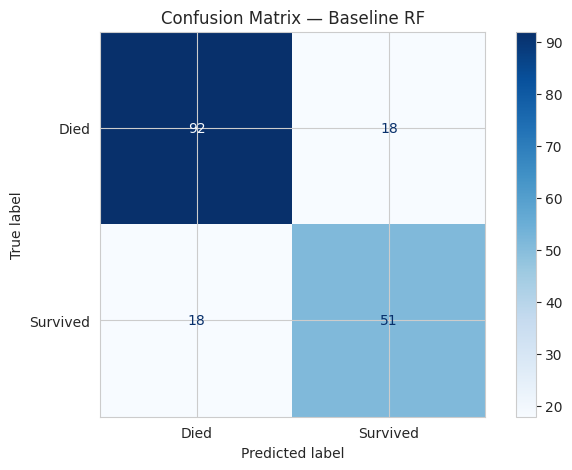


Classification Report:

              precision    recall  f1-score   support

        Died       0.84      0.84      0.84       110
    Survived       0.74      0.74      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [50]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

ConfusionMatrixDisplay(cm, display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title("Confusion Matrix — Baseline RF")
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Died", "Survived"]))

In [51]:
importances = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values(ascending=False)

print("Feature importances:\n")
print(importances)

Feature importances:

Fare          0.234164
Age           0.212465
Sex           0.179251
Title         0.113369
Pclass        0.062171
HasCabin      0.054769
FamilySize    0.048142
Embarked      0.032145
SibSp         0.030125
Parch         0.020565
IsAlone       0.012833
dtype: float64


In [52]:
param_grid = {
    "n_estimators":      [100, 200, 300],
    "max_depth":         [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf":  [1, 2, 4],
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

grid.fit(X_train, y_train)

print("\nBest params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 4))

best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)

Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best CV F1 : 0.7592


=== Tuned model ===
Training accuracy : 0.9087
Testing accuracy  : 0.7821
Precision : 0.7206
Recall    : 0.7101
F1-Score  : 0.7153

              precision    recall  f1-score   support

        Died       0.82      0.83      0.82       110
    Survived       0.72      0.71      0.72        69

    accuracy                           0.78       179
   macro avg       0.77      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



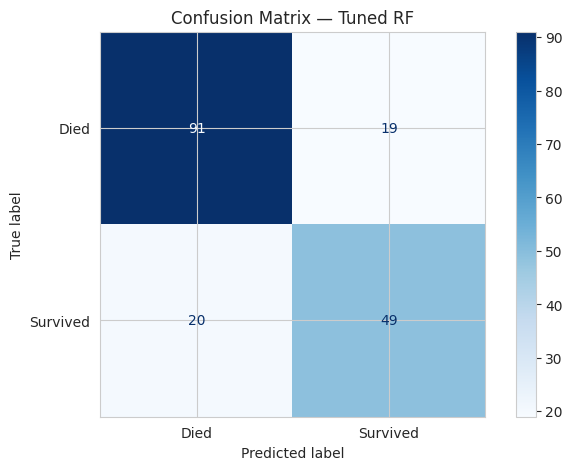

In [53]:
print("=== Tuned model ===")
print("Training accuracy : {:.4f}".format(best_model.score(X_train, y_train)))
print("Testing accuracy  : {:.4f}".format(accuracy_score(y_test, y_pred_best)))
print("Precision : {:.4f}".format(precision_score(y_test, y_pred_best)))
print("Recall    : {:.4f}".format(recall_score(y_test, y_pred_best)))
print("F1-Score  : {:.4f}".format(f1_score(y_test, y_pred_best)))
print()
print(classification_report(y_test, y_pred_best, target_names=["Died", "Survived"]))

cm_best = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm_best, display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title("Confusion Matrix — Tuned RF")
plt.show()

In [54]:
cv_scores = cross_val_score(best_model, X, y, cv=5, scoring="accuracy")

print("5-fold CV accuracy scores:", np.round(cv_scores, 4))
print("Mean : {:.4f}".format(cv_scores.mean()))
print("Std  : {:.4f}".format(cv_scores.std()))

5-fold CV accuracy scores: [0.8212 0.809  0.8708 0.7978 0.8483]
Mean : 0.8294
Std  : 0.0267


/tmp/ipykernel_1842/286100392.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index,
/tmp/ipykernel_1842/286100392.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances_best.values, y=importances_best.index,


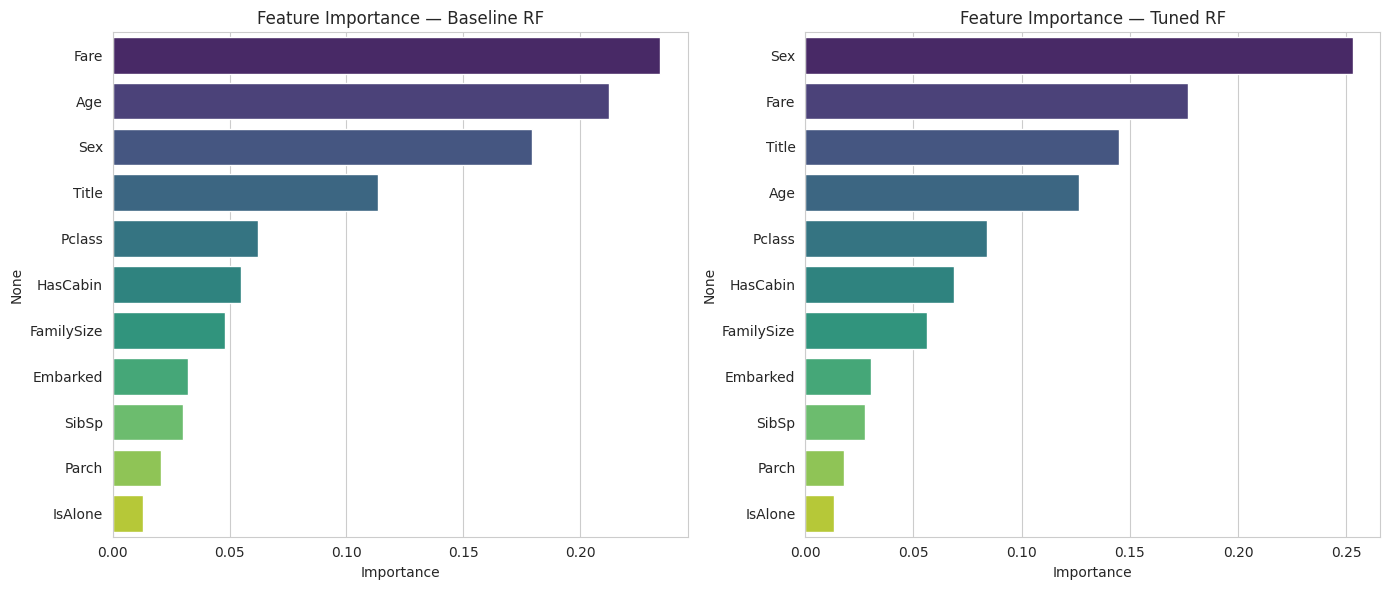

Top 3 features (tuned):
 Sex      0.252915
Fare     0.176668
Title    0.145185
dtype: float64


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=importances.values, y=importances.index,
            palette="viridis", ax=axes[0])
axes[0].set_title("Feature Importance — Baseline RF")
axes[0].set_xlabel("Importance")

importances_best = pd.Series(
    best_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

sns.barplot(x=importances_best.values, y=importances_best.index,
            palette="viridis", ax=axes[1])
axes[1].set_title("Feature Importance — Tuned RF")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

print("Top 3 features (tuned):\n", importances_best.head(3))

In [56]:
print("=== FINAL CONCLUSION ===")
print("Baseline test accuracy:  79.89%")
print("Tuned test accuracy   :  78.21%")
print("Tuned F1              :  0.7153")
print("Best params           :  max_depth=10, min_samples_leaf=1, min_samples_split=10, n_estimators=200")
print("5-fold CV mean ± std  :  0.8294 ± 0.0267")
print("Top 3 features        :  Sex, Fare, Title")

=== FINAL CONCLUSION ===
Baseline test accuracy:  79.89%
Tuned test accuracy   :  78.21%
Tuned F1              :  0.7153
Best params           :  max_depth=10, min_samples_leaf=1, min_samples_split=10, n_estimators=200
5-fold CV mean ± std  :  0.8294 ± 0.0267
Top 3 features        :  Sex, Fare, Title


In [57]:
import joblib
model_path = "/content/titanic_rf_model.joblib"
joblib.dump(best_model, model_path)
print("Model saved to:", model_path)
loaded_model = joblib.load(model_path)
reloaded_preds = loaded_model.predict(X_test)
print("Reload matches tuned preds:", (reloaded_preds == y_pred_best).all())

Model saved to: /content/titanic_rf_model.joblib
Reload matches tuned preds: True
